# Timing sweep: PSFCH processing delay × processing gap, R3 vs R6

**The question.** Campaign v3 hands the PSFCH to the MAC exactly one slot after the PSFCH symbol ends (the stock
5G-LENA "provisional" decode latency) and lets every MAC and controller decision act instantly. Does the
cooperative scheme still work when the timing is made explicit and tighter or looser?

**What is swept** (every run is the campaign-v3 command of the same arm, cell and seed, plus three attributes):

| attribute | values | meaning |
|---|---|---|
| `NrUePhy::SlPsfchProcessingDelay` | 100, 250, 500 µs | end of the PSFCH symbol → feedback at the MAC, every UE (v3: one slot = 500 µs) |
| `NrSlUeMac::CoopActivationDelay` | 50 µs | a decision acts only on slots starting at least this long after it |
| `NrSlUeMac::MinTimeGapProcessing` | 2, 3, 4 slots | processing gap of the resource selection; with PSFCH gap 3, reserved copies are ≥ 3 + gap slots apart (v3: 2 → 5 slots) |

**Arms.** R3: source Option 2 (NACK-only HARQ, no helper). R6: cooperative scheme (Option 2 with a Kuo helper,
takeover on a helper NACK, fallback on a silent helper).

**Stages.** A: 0 background vehicles, 3 routes × 2 traffic types, seeds 1–10 (1080 runs). B: 60 background
vehicles, 3 routes, aperiodic traffic, seeds 1–3 (162 runs). All 1242 runs completed.

**What a missed deadline does** (counters in `_run.csv`, all per 1000 packets below):

| counter | event | consequence |
|---|---|---|
| `cancel_late` | the source learns of the all-ACK too late to withdraw its next reserved copy | one extra transmission, no reliability loss |
| `helper_fb_late` | a member's PSFCH reaches the helper too late to gate its next relay slot | the helper does not relay in that slot; the source's takeover or fallback covers it |
| `takeover_late` | the source learns of a helper NACK too late for the next slot and takes a later one | recovery later, if a slot is left |
| `*_late_no_slot` | as above, with no reserved slot left | that recovery is lost |
| `fallback_late` | the source's fallback decision misses the next slot | as for takeover |

In [1]:
import glob, numpy as np, pandas as pd, matplotlib.pyplot as plt, os
FIG = 'figures/timing'; os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})
ARM = {'R3': '#4C78A8', 'R6': '#E45756'}
d = pd.read_csv('out/timing/summary.csv')
d['bg'] = np.where(d.cell.str.contains('moderate'), 60, 0)
d['ctx'] = d.cell.str.replace(r'_s\d+$', '', regex=True)
d['setting'] = 'd' + d.delay_us.astype(str) + ' g' + d.gap.astype(str)
SETTINGS = [f'd{x} g{g}' for x in (100, 250, 500) for g in (2, 3, 4)]
v = []
for arm in ('R3', 'R6'):
    for cell in d.cell.unique():
        f = glob.glob(f'out/remote_v3/{arm}/{cell}_run.csv*')
        if f:
            v.append(pd.read_csv(f[0]).iloc[0].to_dict() | {'arm': arm, 'cell': cell})
v = pd.DataFrame(v); v['bg'] = np.where(v.cell.str.contains('moderate'), 60, 0)
print(len(d), 'sweep runs;', len(v), 'v3 baseline runs')
d.groupby(['bg', 'arm']).size().unstack()

1242 sweep runs; 138 v3 baseline runs


arm,R3,R6
bg,,
0,540,540
60,81,81


## 1. Reproduction: a shorter delay changes nothing

At gap 2, the 100 µs and 250 µs runs reproduce campaign v3 exactly, run by run (every KPI column v3 has, wall
time aside), although v3 uses a one-slot delay and no activation deadline. The reason is that a decision can only
act on a later reserved slot, and the selection already keeps the copies of a TB at least 5 slots apart: getting
the feedback earlier frees no earlier slot. Gap 3 and 4 are also identical across the three delays. At 500 µs
and gap 2, only the 3 runs in which no deadline was missed are unchanged.

In [2]:
skip = {'wall_s', 'sel_cpu_us_mean'}
common = [c for c in v.columns if c in d.columns and c not in skip | {'arm', 'cell', 'bg'}]
rows = []
for s in ('d100 g2', 'd250 g2', 'd500 g2'):
    x = d[d.setting == s].merge(v, on=['arm', 'cell'], suffixes=('', '_v3'))
    diff = [(x[c].astype(str) != x[c + '_v3'].astype(str)) for c in common]
    rows.append(dict(setting=s, runs=len(x), runs_identical_to_v3=int((~np.any(diff, axis=0)).sum())))
for g in (2, 3, 4):
    a = d[(d.delay_us == 100) & (d.gap == g)].set_index(['arm', 'cell'])
    for x in (250, 500):
        b = d[(d.delay_us == x) & (d.gap == g)].set_index(['arm', 'cell']).loc[a.index]
        same = (a[common].astype(str) == b[common].astype(str)).all(axis=1)
        rows.append(dict(setting=f'd{x} g{g} vs d100 g{g}', runs=len(a), runs_identical_to_v3=np.nan,
                         runs_identical_to_d100=int(same.sum())))
pd.DataFrame(rows)

,setting,runs,runs_identical_to_v3,runs_identical_to_d100
0,d100 g2,138,138.0,NaN
1,d250 g2,138,138.0,NaN
2,d500 g2,138,3.0,NaN
3,d250 g2 vs d100 g2,138,NaN,138.0
4,d500 g2 vs d100 g2,138,NaN,3.0
5,d250 g3 vs d100 g3,138,NaN,138.0
6,d500 g3 vs d100 g3,138,NaN,138.0
7,d250 g4 vs d100 g4,138,NaN,138.0
8,d500 g4 vs d100 g4,138,NaN,138.0


## 2. Missed deadlines

Only one setting misses deadlines: **500 µs at gap 2**. The real budget from the end of the PSFCH symbol to the
start of the next reserved slot (m+5) is about 536 µs at 30 kHz, so 500 + 50 µs does not fit and 250 + 50 µs does.
One more slot of gap (6-slot spacing) gives a full extra 500 µs and removes every late event.

In [3]:
LATE = ['cancel_late', 'helper_fb_late', 'takeover_late', 'takeover_late_no_slot', 'fallback_late',
        'fallback_late_no_slot']
g = d.groupby(['bg', 'arm', 'setting'])
L = (g[LATE].sum().div(g.pkts.sum(), axis=0) * 1000).round(2)
L = L[L.sum(axis=1) > 0]
print('late events per 1000 packets (settings with none are omitted)')
L

late events per 1000 packets (settings with none are omitted)


cancel_late  helper_fb_late  takeover_late  \
bg arm setting                                               
0  R3  d500 g2        90.33            0.00           0.00   
   R6  d500 g2         0.00         1747.68           8.34   
60 R3  d500 g2        59.84            0.00           0.00   
   R6  d500 g2         0.00         1475.16          30.87   

                takeover_late_no_slot  fallback_late  fallback_late_no_slot  
bg arm setting                                                               
0  R3  d500 g2                   0.00            0.0                    0.0  
   R6  d500 g2                   2.12            0.0                    0.0  
60 R3  d500 g2                   0.00            0.0                    0.0  
   R6  d500 g2                   5.05            0.0                    0.0

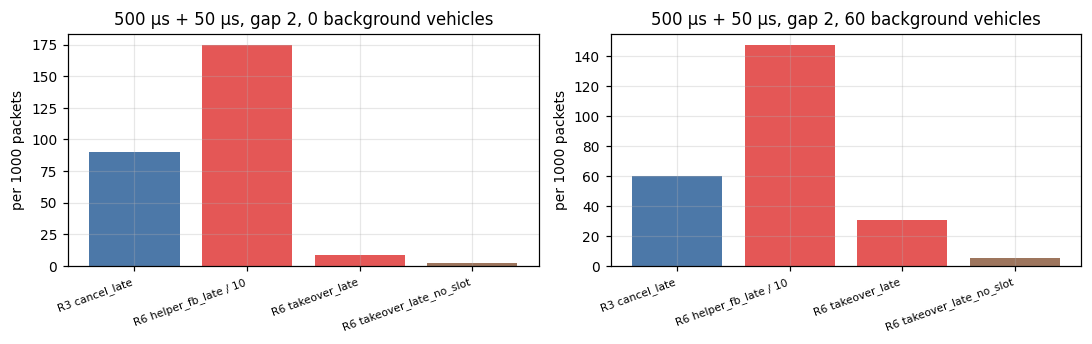

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=False)
x = d[d.setting == 'd500 g2']
for i, bg in enumerate((0, 60)):
    y = x[x.bg == bg]
    r3 = y[y.arm == 'R3']; r6 = y[y.arm == 'R6']
    vals = {'R3 cancel_late': r3.cancel_late.sum() / r3.pkts.sum(),
            'R6 helper_fb_late / 10': r6.helper_fb_late.sum() / r6.pkts.sum() / 10,
            'R6 takeover_late': r6.takeover_late.sum() / r6.pkts.sum(),
            'R6 takeover_late_no_slot': r6.takeover_late_no_slot.sum() / r6.pkts.sum()}
    ax[i].bar(range(len(vals)), np.array(list(vals.values())) * 1000,
              color=[ARM['R3'], ARM['R6'], ARM['R6'], '#9D755D'])
    ax[i].set_xticks(range(len(vals))); ax[i].set_xticklabels(vals.keys(), rotation=20, ha='right', fontsize=7)
    ax[i].set_ylabel('per 1000 packets'); ax[i].set_title(f'500 µs + 50 µs, gap 2, {bg} background vehicles')
fig.tight_layout(); fig.savefig(f'{FIG}/late_events.pdf'); plt.show()

## 3. What the missed deadlines cost

Paired by run (same arm, cell and seed), against 100 µs at the same gap. Mean ± standard error over the runs.

In [5]:
K = {'prr_mean': 100, 'prr_min': 100, 'tx_per_pkt': 1}
def paired(a, b):
    p = d.pivot_table(index=['arm', 'bg', 'cell'], columns='setting', values=list(K))
    out = []
    for (arm, bg), q in p.groupby(level=[0, 1]):
        r = dict(compare=f'{a} − {b}', arm=arm, bg=bg, runs=len(q))
        for k, s in K.items():
            x = s * (q[(k, a)] - q[(k, b)])
            r[k] = f'{x.mean():+.3f} ± {x.std() / np.sqrt(len(x)):.3f}'
        out.append(r)
    return out
pd.DataFrame(paired('d500 g2', 'd100 g2')).set_index(['compare', 'arm', 'bg'])

runs        prr_mean         prr_min      tx_per_pkt
compare           arm bg                                                      
d500 g2 − d100 g2 R3  0     60  -0.210 ± 0.203  -0.783 ± 0.479  +0.040 ± 0.006
                      60     9  -0.409 ± 0.439  +0.439 ± 1.584  +0.018 ± 0.016
                  R6  0     60  -0.050 ± 0.186  +0.224 ± 0.513  +0.065 ± 0.010
                      60     9  -0.337 ± 0.878  -1.122 ± 1.712  +0.025 ± 0.016

The late events cost transmissions, not reliability: +0.04 to +0.065 transmissions per packet with 0 background
vehicles, while the PRR changes stay within one standard error. A late cancel is a copy sent anyway; a late
helper relay gate is covered by the source; a recovery with no slot left (2 to 5 per 1000 packets for R6) is rare.

## 4. Does a larger processing gap help?

Again paired by run, against gap 2, at 100 µs (no late events at any gap).

In [6]:
pd.DataFrame(paired('d100 g3', 'd100 g2') + paired('d100 g4', 'd100 g2')).set_index(['compare', 'arm', 'bg'])

runs        prr_mean         prr_min      tx_per_pkt
compare           arm bg                                                      
d100 g3 − d100 g2 R3  0     60  +0.020 ± 0.192  +0.313 ± 0.530  -0.006 ± 0.004
                      60     9  -0.695 ± 0.410  +0.539 ± 1.347  -0.020 ± 0.010
                  R6  0     60  +0.474 ± 0.224  +1.603 ± 0.614  -0.010 ± 0.005
                      60     9  +0.640 ± 0.688  -0.189 ± 0.758  +0.023 ± 0.016
d100 g4 − d100 g2 R3  0     60  +0.438 ± 0.224  +0.124 ± 0.483  -0.012 ± 0.004
                      60     9  -0.688 ± 0.383  +0.562 ± 1.172  -0.027 ± 0.008
                  R6  0     60  +0.380 ± 0.218  +1.313 ± 0.609  +0.000 ± 0.004
                      60     9  +0.544 ± 0.612  +1.066 ± 0.808  -0.008 ± 0.018

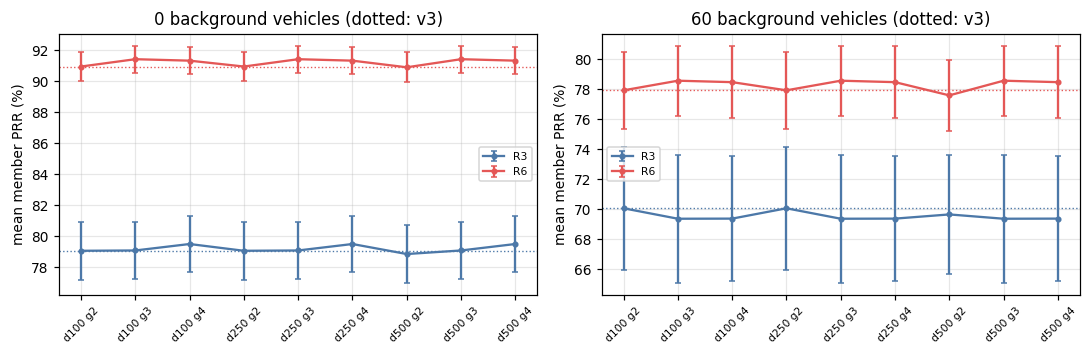

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for i, bg in enumerate((0, 60)):
    for arm in ('R3', 'R6'):
        y = d[(d.bg == bg) & (d.arm == arm)].groupby('setting').prr_mean
        m, se = y.mean().reindex(SETTINGS) * 100, (y.std() / np.sqrt(y.size())).reindex(SETTINGS) * 100
        ax[i].errorbar(range(len(SETTINGS)), m, yerr=se, fmt='-o', ms=3, capsize=2, color=ARM[arm], label=arm)
        b = v[(v.bg == bg) & (v.arm == arm)].prr_mean.mean() * 100
        ax[i].axhline(b, color=ARM[arm], ls=':', lw=0.9)
    ax[i].set_xticks(range(len(SETTINGS))); ax[i].set_xticklabels(SETTINGS, rotation=45, fontsize=7)
    ax[i].set_ylabel('mean member PRR (%)'); ax[i].set_title(f'{bg} background vehicles (dotted: v3)')
    ax[i].legend(fontsize=7)
fig.tight_layout(); fig.savefig(f'{FIG}/prr_by_setting.pdf'); plt.show()

## 5. The cooperative gain under every timing setting

R6 − R3, mean member PRR and worst member PRR (pp), per setting and per context.

In [8]:
p = d.pivot_table(index=['bg', 'setting'], columns='arm', values=['prr_mean', 'prr_min'])
G = pd.DataFrame({'gain prr_mean (pp)': 100 * (p[('prr_mean', 'R6')] - p[('prr_mean', 'R3')]),
                  'gain prr_min (pp)': 100 * (p[('prr_min', 'R6')] - p[('prr_min', 'R3')])}).round(2)
G.unstack(0)

gain prr_mean (pp)       gain prr_min (pp)       
bg                      0     60                0      60
setting                                                  
d100 g2              11.92  7.86             22.70  20.56
d100 g3              12.37  9.19             23.99  19.84
d100 g4              11.86  9.09             23.89  21.07
d250 g2              11.92  7.86             22.70  20.56
d250 g3              12.37  9.19             23.99  19.84
d250 g4              11.86  9.09             23.89  21.07
d500 g2              12.08  7.93             23.71  19.00
d500 g3              12.37  9.19             23.99  19.84
d500 g4              11.86  9.09             23.89  21.07

In [9]:
q = d[d.setting.isin(['d100 g2', 'd500 g2', 'd500 g3'])].pivot_table(index=['bg', 'ctx'], columns=['setting', 'arm'],
                                                                     values='prr_mean')
pd.DataFrame({s: 100 * (q[(s, 'R6')] - q[(s, 'R3')]) for s in ('d100 g2', 'd500 g2', 'd500 g3')}).round(2)

d100 g2  d500 g2  d500 g3
bg ctx                                                        
0  hwy_ivd30_aperiodic1tb_none          1.38     1.46     1.32
   hwy_ivd30_periodic1tb_none           0.64     0.58     0.53
   rbtE_ivd30_aperiodic1tb_none        18.66    18.41    18.39
   rbtE_ivd30_periodic1tb_none         16.66    18.47    17.46
   rbt_ivd30_aperiodic1tb_none         16.37    14.80    17.84
   rbt_ivd30_periodic1tb_none          17.81    18.75    18.71
60 hwy_ivd30_aperiodic1tb_moderate     -0.82    -0.04    -0.07
   rbtE_ivd30_aperiodic1tb_moderate    14.70    13.62    15.48
   rbt_ivd30_aperiodic1tb_moderate      9.70    10.21    12.18

## 6. Conclusions

- **Deadlines are met at the standard spacing when the PSFCH is processed within 250 µs.** With 100 or 250 µs
  plus 50 µs of activation, gap 2 (5-slot spacing) has no late event of any kind, and every run is identical to
  campaign v3. Faster processing brings nothing more, because the next usable slot is fixed by the selection.
- **A full-slot decode (500 µs) at gap 2 misses deadlines,** for both arms: R3 sends copies it could not cancel
  (90 per 1000 packets at 0 background), R6's helper misses relay gates and the source takes over late.
- **The cost is extra transmissions, not reliability.** +0.04 (R3) and +0.065 (R6) transmissions per packet with
  no background traffic; the PRR changes are within one standard error.
- **One extra slot of gap removes every late event** at 500 + 50 µs.
- **The cooperative gain is unchanged by timing:** R6 − R3 stays about +12 pp mean PRR with no background traffic
  and +8 to +9 pp with 60 vehicles, in every setting. As in v3 it comes from the roundabouts (+15 to +19 pp with
  no background traffic); on the highway, where the source reaches every member, it stays within about ±1.5 pp
  in every setting.
- **Gap 3 or 4 slightly helps R6 with no background traffic** (about +0.4 to +0.5 pp mean, +1.3 to +1.6 pp worst
  member, about two standard errors). With 60 vehicles three seeds are too few to tell.

**For the paper.** State the timing assumption explicitly: PSFCH decoded within 250 µs and 50 µs of
preparation fit the 5-slot spacing with no change in results. A UE that needs a full slot either accepts a few extra
transmissions or uses a 6-slot spacing, with no loss of the cooperative gain.

**Limits.** Stage B has 3 seeds and aperiodic traffic only. The activation delay is one value (50 µs). The model's
MAC and controller still take zero time within the activation budget.